# 0420 · Interpretabilidad y hallazgos operativos · versión 5 (OE5)

**Qué hace.** Interpreta los modelos de la decisión registrada (`P4b_decision_v2.json`: Random Forest para clasificación y LightGBM L1 para regresión), tal como los entrenó `0416_PruebaUnica_Reserva`, sin volver a ajustar nada.

| Sección | Pregunta que responde | Salida |
| --- | --- | --- |
| 1. Estabilidad | ¿Pesan las mismas variables en los cinco bloques de validación (abril a agosto)? | `01_*` |
| 2. Permutación en prueba | ¿Cuánto empeora el modelo si se desordena cada variable en la prueba sep–oct? | `02_*` |
| 3. SHAP | ¿Qué variables mueven cada predicción y en qué dirección? | `03_*` |
| 4. Dependencia y categorías | ¿Cómo cambia el efecto con el valor de la variable o la categoría? | `04_*` |
| 5. Traducción operativa | Con k = 500 alertas por día: dónde se concentran, cuántos incumplimientos se escapan, por qué se alerta y con qué margen de error se comunica el tiempo | `05_*` a `07_*` |

**Lectura.** Las importancias y los SHAP describen **cómo usa el modelo** las variables; no son efectos causales (realimentación OE5). Sobre la prueba se interpreta **solo el modelo final ya fijado**.

**Requisitos.** Haber ejecutado `0416_PruebaUnica_Reserva` (carpeta `V4/MODELOS/` y `P4d_EJECUTADA.json`). Este cuaderno solo lee: no vuelve a correr la prueba ni cambia la decisión.

**Salidas.** CSV y PNG en `REVISION_2026_11/V4/INTERPRETACION/`. Solo agregados; ninguna guía individual.

> **Versión 5 (08-11-2026).** Lee la base V4 y la decisión v2. La carga operativa ya no usa un umbral global: aplica la regla registrada de capacidad fija (k alertas por día, C4) y reporta k = 250, 500 y 1.000. La estabilidad se mide en los cinco bloques de validación (abril a agosto). El resto del análisis es el de la versión 4.

In [0]:
# Si faltan librerías:
# %pip install shap lightgbm xgboost scikit-learn joblib

In [0]:
%pip install "duckdb<2" lightgbm xgboost shap
dbutils.library.restartPython()

Looking in indexes: [REDACTED]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.5/19.5 MB 119.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 138.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.2/57.2 MB 167.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 547.3/547.3 kB 18.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 305.1/305.1 MB 116.6 MB/s  0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [shap]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


## 0. Configuración

In [0]:
import os, json, numpy as np, pandas as pd, joblib, matplotlib.pyplot as plt, shap
from sklearn.inspection import permutation_importance

# MODULOS/ debe estar junto al cuaderno, como en 0100 (MODULOS/conexion_sql.py)
from MODULOS.interpretabilidad import (shap_modelo, agregar_por_variable, estabilidad_importancias, resumen_shap_tarea,
                                       efectos_por_categoria, alertas_por_segmento, barras_horizontales)
from MODULOS.modelado_temporal import alertas_por_capacidad

In [0]:
PATH_DATABRICKS = "/Volumes/proyectogrado/source/source/"
CARPETA_SALIDAS = f"{PATH_DATABRICKS}LOG_CONSOLIDADO/REVISION_2026_11/V4/"
CARPETA_MODELOS = f"{CARPETA_SALIDAS}MODELOS/"
CARPETA_INT     = f"{CARPETA_SALIDAS}INTERPRETACION/"
os.makedirs(CARPETA_INT, exist_ok=True)
SEMILLA = 42
N_SHAP = 2000            # filas de prueba para SHAP (Random Forest es lento: bajar a 1000 si tarda)
N_PERMUTACION = 20_000   # filas de prueba para la importancia por permutación
TOP = 15                 # variables que se muestran en los gráficos
assert os.path.exists(f"{CARPETA_SALIDAS}PRUEBA/P4d_EJECUTADA.json"), "Primero debe haberse ejecutado 0416_PruebaUnica_Reserva"

In [0]:
# Decisión registrada (v2): modelos, regla de alertas y variables
DEC = json.load(open(f"{CARPETA_SALIDAS}P4b_decision_v2.json"))
CAT, NUM = DEC["variables_categoricas"], DEC["variables_numericas"]
K = DEC["regla_alertas"]["k_por_dia"]; KS = DEC["regla_alertas"]["sensibilidad_k"]
print(json.dumps({k: DEC[k] for k in ["modelo_clf", "modelo_reg", "version", "calibracion", "regla_alertas"]}, indent=1, ensure_ascii=False))

{
 "modelo_clf": "RandomForest",
 "modelo_reg": "LightGBM",
 "version": "internas",
 "calibracion": "ninguna",
 "regla_alertas": {
  "tipo": "capacidad_fija_por_dia",
  "k_por_dia": 500,
  "sensibilidad_k": [
   250,
   500,
   1000
  ],
  "umbral_global_equivalente_solo_referencia": 0.23086920380592346
 }
}


## 1. Estabilidad de la importancia entre bloques de validación

Usa la importancia por permutación que midieron 0413 a 0415 en cada uno de los cinco bloques de validación (abril a agosto). Para cada modelo y tarea compara el orden de las variables entre bloques con la correlación de Spearman. Cercano a 1: el orden se mantiene; por debajo de 0,5: interpretar con cautela.

In [0]:
imp = pd.read_csv(f"{CARPETA_SALIDAS}P4b_importancia_pliegues.csv")
filas = []
for (tarea, modelo), g in imp.groupby(["tarea", "modelo"]):
    piv, resumen = estabilidad_importancias(g)
    filas.append({"tarea": tarea, "modelo": modelo, **resumen})
    piv.assign(media=piv.mean(axis=1)).sort_values("media", ascending=False).round(5) \
       .to_csv(f"{CARPETA_INT}01_permutacion_validacion_{tarea}_{modelo}.csv")

In [0]:
estabilidad = pd.DataFrame(filas); display(estabilidad)
estabilidad.to_csv(f"{CARPETA_INT}01_estabilidad_importancias.csv", index=False)

tarea,modelo,spearman_min_entre_bloques,spearman_medio,top5_promedio,variables_top5_en_todos_los_bloques
clf,LightGBM,0.49473684210526314,0.6747368421052632,"margen_sla_en_t0_h, dia_semana, hist_inc_zona_franja, categoria_zona, ID_PRODUCTO","categoria_zona, dia_semana, margen_sla_en_t0_h"
clf,RandomForest,0.5614035087719299,0.7812280701754386,"margen_sla_en_t0_h, dia_semana, categoria_zona, hist_h_zona_franja, hist_inc_zona_franja","dia_semana, hist_h_zona_franja, hist_inc_zona_franja, margen_sla_en_t0_h"
clf,XGBoost,0.4666666666666667,0.6849122807017544,"margen_sla_en_t0_h, dia_semana, categoria_zona, hist_inc_zona_franja, hist_h_zona_franja","categoria_zona, dia_semana, hist_inc_zona_franja, margen_sla_en_t0_h"
reg,LightGBM,0.8596491228070176,0.9036842105263159,"hist_h_zona_franja, categoria_zona, margen_sla_en_t0_h, dia_semana, hist_inc_zona_franja","categoria_zona, dia_semana, hist_h_zona_franja, margen_sla_en_t0_h"
reg,RandomForest,0.8947368421052632,0.9222807017543859,"categoria_zona, hist_h_zona_franja, hist_inc_zona_franja, margen_sla_en_t0_h, hist_inc_cliente","categoria_zona, hist_h_zona_franja"
reg,XGBoost,0.8228070175438595,0.9231578947368421,"hist_h_zona_franja, margen_sla_en_t0_h, categoria_zona, hist_inc_zona_franja, dia_semana","dia_semana, hist_h_zona_franja, hist_inc_zona_franja, margen_sla_en_t0_h"


## 2. Importancia por permutación del modelo de la decisión (prueba sep–oct)

Se cargan los modelos y los datos de prueba que dejó `0416_PruebaUnica_Reserva`. Luego se desordena cada variable en una muestra de la prueba y se mide cuánto cae la AP (clasificación) o sube el MAE (regresión).

In [0]:
modelos, datos = {}, {}
for tarea in ["clf", "reg"]:
    modelos[tarea] = joblib.load(f"{CARPETA_MODELOS}modelo_final_{tarea}.joblib")
    datos[tarea] = pd.read_parquet(f"{CARPETA_MODELOS}prueba_{tarea}.parquet")
    print(f"{tarea}: {DEC['modelo_' + tarea]} · {len(datos[tarea]):,} guías de prueba")
    datos[tarea]["y"] = datos[tarea]["y"].astype(float)

clf: RandomForest · 409,137 guías de prueba
reg: LightGBM · 406,259 guías de prueba


In [0]:
perm = []
for tarea, scoring in [("clf", "average_precision"), ("reg", "neg_mean_absolute_error")]:
    d = datos[tarea].sample(min(N_PERMUTACION, len(datos[tarea])), random_state=SEMILLA)
    r = permutation_importance(modelos[tarea], d[CAT + NUM], d["y"], n_repeats=5, random_state=SEMILLA, scoring=scoring, n_jobs=1)
    t = pd.DataFrame({"tarea": tarea, "variable": CAT + NUM, "importancia": r.importances_mean, "desv": r.importances_std}) \
          .sort_values("importancia", ascending=False)
    perm.append(t)
perm = pd.concat(perm); perm.to_csv(f"{CARPETA_INT}02_permutacion_prueba.csv", index=False)
display(perm.groupby("tarea").head(10).round(4))

tarea,variable,importancia,desv
clf,margen_sla_en_t0_h,0.0764,0.0023
clf,dia_semana,0.0656,0.0019
clf,hist_inc_zona_franja,0.021,0.0056
clf,categoria_zona,0.0208,0.007
clf,hist_h_zona_franja,0.0186,0.0037
clf,hist_inc_cliente,0.0092,8.0E-4
clf,ID_PRODUCTO,0.0084,0.0021
clf,n_hist_cliente,0.0063,0.0012
clf,hist_h_cliente,0.0042,0.0012
clf,h_admision_a_t0,0.0021,8.0E-4


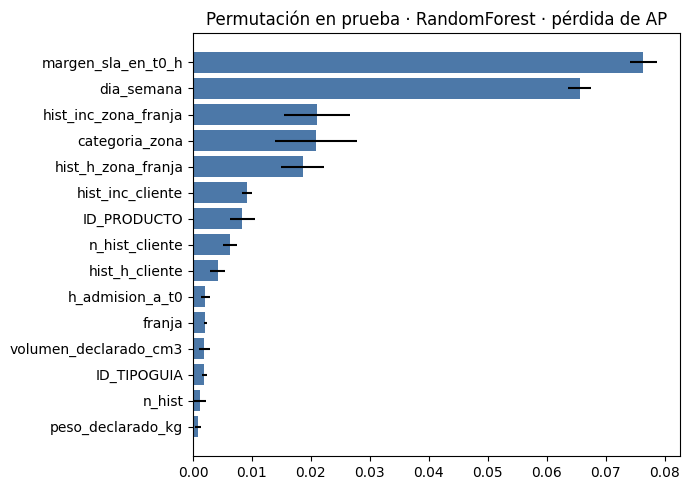

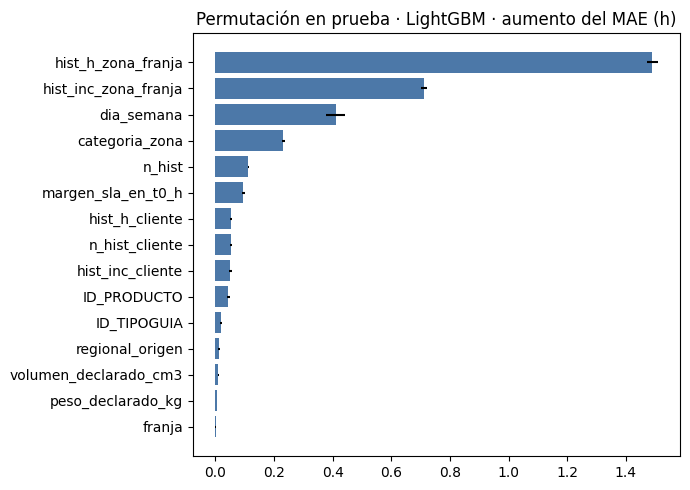

In [0]:
for tarea in ["clf", "reg"]:
    tt = perm[perm.tarea == tarea].head(TOP)[::-1]
    medida = "pérdida de AP" if tarea == "clf" else "aumento del MAE (h)"
    barras_horizontales(tt.variable, tt.importancia, f"Permutación en prueba · {DEC['modelo_' + tarea]} · {medida}",
                        f"{CARPETA_INT}02_permutacion_prueba_{tarea}.png", error=tt.desv)

## 3. Valores SHAP

SHAP reparte cada predicción entre las variables. Para una variable categórica se suman sus columnas *one-hot*. En clasificación, los valores están en la escala del modelo (log-odds en los ensambles de *boosting* y en la logística; probabilidad en Random Forest). La **dirección** de una variable numérica es la correlación de Spearman entre su valor y su SHAP: positiva significa «a mayor valor, mayor riesgo o más horas».

### 3.1 Cálculo

Una muestra de `N_SHAP` guías de prueba por tarea; el fondo (necesario para el modelo lineal) sale de la muestra de entrenamiento que guardó 0416_PruebaUnica_Reserva.

In [0]:
SHAP, SHAP_COLUMNAS = {}, {}
for tarea in ["clf", "reg"]:
    d = datos[tarea].sample(min(N_SHAP, len(datos[tarea])), random_state=SEMILLA)
    fondo = pd.read_parquet(f"{CARPETA_MODELOS}muestra_entrenamiento_{tarea}.parquet").sample(500, random_state=SEMILLA)
    sv, nombres, Xt = shap_modelo(modelos[tarea], d[CAT + NUM], fondo[CAT + NUM], tarea)
    agg = agregar_por_variable(sv, nombres, CAT); agg.index = d.index
    SHAP[tarea] = (d, agg)                      # por variable original
    SHAP_COLUMNAS[tarea] = (sv, nombres, Xt)    # por columna transformada

### 3.2 Resumen por variable

In [0]:
resumen_shap = pd.concat([resumen_shap_tarea(tarea, *SHAP[tarea], NUM) for tarea in ["clf", "reg"]])
resumen_shap.to_csv(f"{CARPETA_INT}03_shap_por_variable.csv", index=False)
display(resumen_shap.groupby("tarea").head(10).round(4))

/Workspace/Users/john.cienciadatos@yahoo.com/(Clone) PROYECTO_DE_GRADO_V_2/PROYECTO_DE_GRADO_ML-/MODULOS/interpretabilidad.py:53: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  direccion = spearmanr(d[v], agg[v], nan_policy="omit").correlation if v in numericas else np.nan


tarea,variable,media_abs_shap,direccion_spearman
clf,margen_sla_en_t0_h,0.0184,-0.9329
clf,dia_semana,0.0174,null
clf,n_hist,0.0157,0.715
clf,hist_h_zona_franja,0.0148,0.341
clf,categoria_zona,0.0125,null
clf,hist_inc_zona_franja,0.0112,0.3413
clf,n_hist_cliente,0.0107,0.8392
clf,hist_h_cliente,0.0063,0.7516
clf,ID_PRODUCTO,0.0057,null
clf,hist_inc_cliente,0.0051,0.7722


### 3.3 Gráficos

Barras: rojo si la variable aumenta el riesgo o las horas al crecer, azul si las disminuye, gris si es categórica. El gráfico de resumen muestra cada columna transformada.

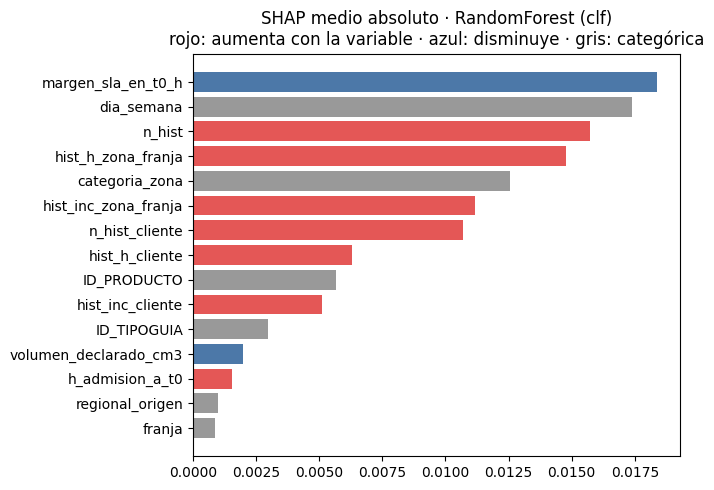

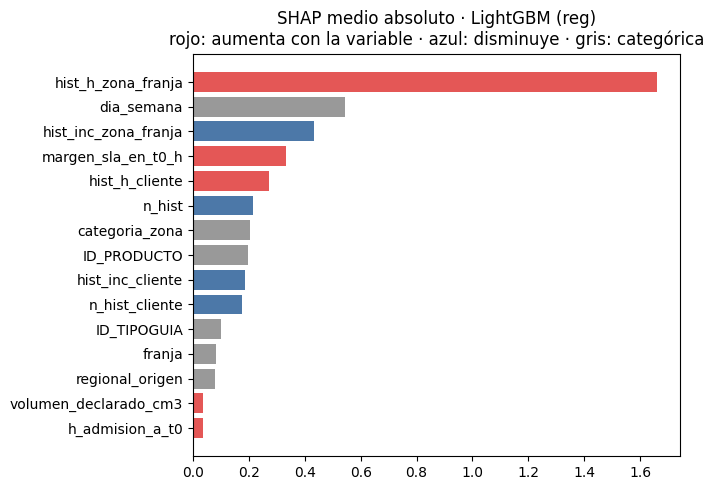

In [0]:
for tarea in ["clf", "reg"]:
    tt = resumen_shap[resumen_shap.tarea == tarea].head(TOP)[::-1]
    colores = np.where(tt.direccion_spearman > 0, "#E45756", np.where(tt.direccion_spearman < 0, "#4C78A8", "#999"))
    barras_horizontales(tt.variable, tt.media_abs_shap,
                        f"SHAP medio absoluto · {DEC['modelo_' + tarea]} ({tarea})\nrojo: aumenta con la variable · azul: disminuye · gris: categórica",
                        f"{CARPETA_INT}03_shap_barras_{tarea}.png", color=colores)

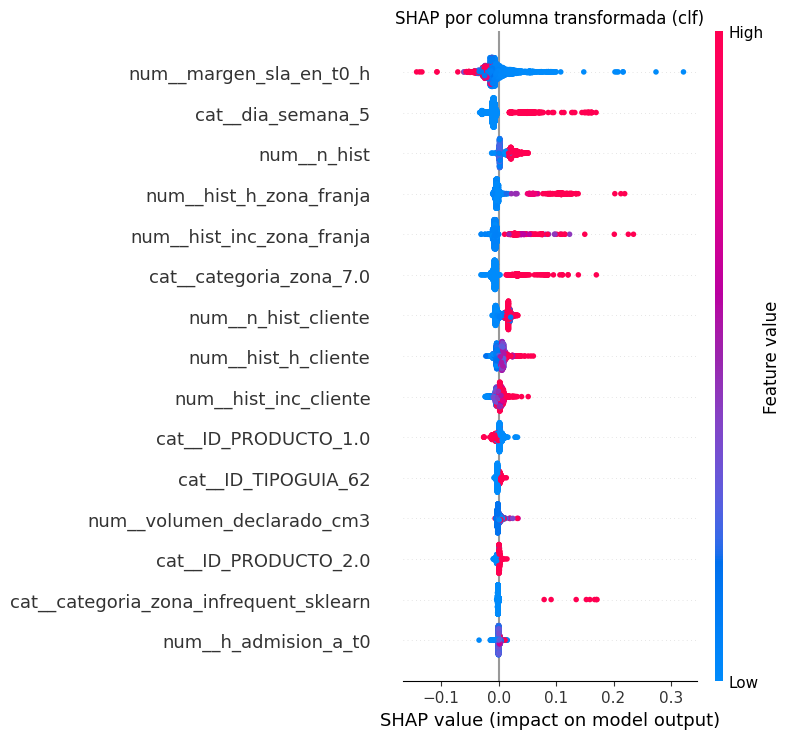

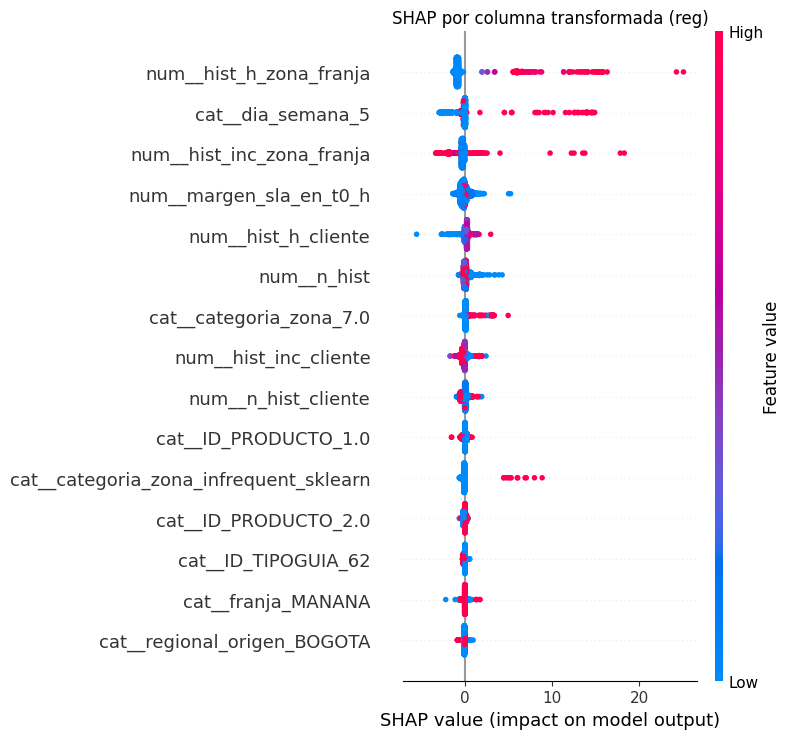

In [0]:
for tarea in ["clf", "reg"]:
    sv, nombres, Xt = SHAP_COLUMNAS[tarea]
    plt.figure(); shap.summary_plot(sv, Xt, feature_names=nombres, max_display=TOP, show=False)
    plt.title(f"SHAP por columna transformada ({tarea})"); plt.tight_layout()
    plt.savefig(f"{CARPETA_INT}03_shap_resumen_{tarea}.png", dpi=130, bbox_inches="tight"); plt.show()

## 4. Dependencia y efecto por categoría

### 4.1 Dependencia de las tres variables numéricas con más peso

Cada punto es una guía: valor de la variable (eje x) frente a su SHAP (eje y).

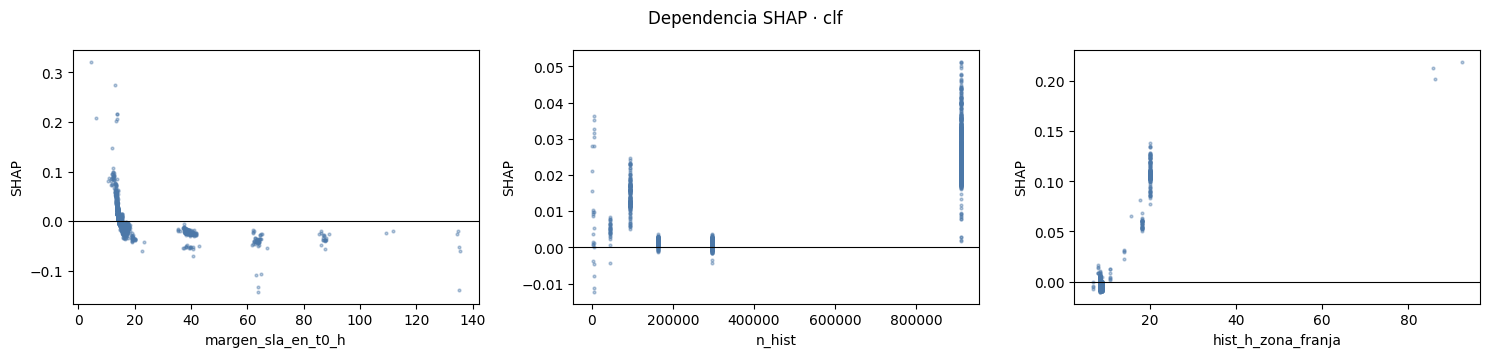

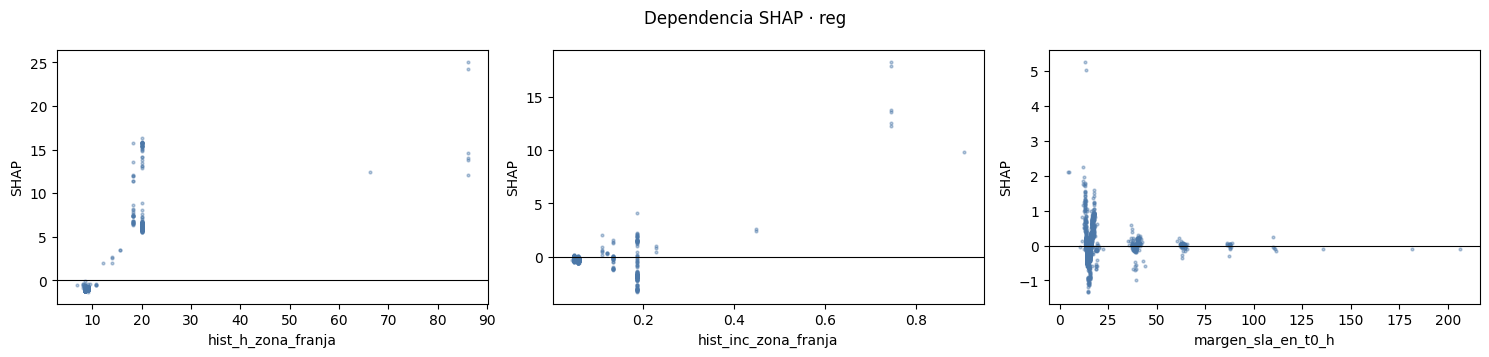

In [0]:
for tarea in ["clf", "reg"]:
    d, agg = SHAP[tarea]
    top_num = [v for v in resumen_shap[resumen_shap.tarea == tarea].variable if v in NUM][:3]
    fig, axs = plt.subplots(1, len(top_num), figsize=(5 * len(top_num), 3.6), squeeze=False)
    for ax, v in zip(axs[0], top_num):
        ax.scatter(d[v], agg[v], s=4, alpha=0.4, color="#4C78A8"); ax.axhline(0, color="k", lw=0.8)
        ax.set_xlabel(v); ax.set_ylabel("SHAP")
    fig.suptitle(f"Dependencia SHAP · {tarea}"); plt.tight_layout()
    fig.savefig(f"{CARPETA_INT}04_dependencia_{tarea}.png", dpi=130); plt.show()

### 4.2 SHAP medio por categoría (categorías con al menos 30 guías)

In [0]:
filas = []
for tarea in ["clf", "reg"]:
    filas += efectos_por_categoria(tarea, *SHAP[tarea], CAT)
efectos_cat = pd.DataFrame(filas).sort_values(["tarea", "variable", "shap_medio"])
efectos_cat.to_csv(f"{CARPETA_INT}04_shap_por_categoria.csv", index=False)
display(efectos_cat.round(4).head(30))

tarea,variable,categoria,n,shap_medio
clf,ID_PRODUCTO,1.0,526,-0.0098
clf,ID_PRODUCTO,6.0,243,-0.0011
clf,ID_PRODUCTO,2.0,1142,0.0043
clf,ID_TIPOGUIA,61,967,-0.0029
clf,ID_TIPOGUIA,43,206,-0.0019
clf,ID_TIPOGUIA,44,98,-0.0016
clf,ID_TIPOGUIA,62,677,0.0032
clf,categoria_zona,3.0,236,-0.0088
clf,categoria_zona,1.0,1075,-0.0087
clf,categoria_zona,6.0,455,-0.0074


## 5. Traducción operativa

### 5.1 Carga de alertas con la regla registrada (k alertas por día)

Cada día se alertan las k guías con mayor riesgo (k = 500 es la regla de la decisión; 250 y 1.000 son sensibilidad). La precisión y la exhaustividad deben coincidir con `P4d_capacidad.csv`.

In [0]:
c = datos["clf"].copy()
c["mes"] = pd.to_datetime(c.dia).dt.strftime("%Y-%m")
dias = c.dia.nunique()
filas = []
for k in KS:
    a = alertas_por_capacidad(c.pred, c.dia, k)
    filas.append({"k_por_dia": k, "regla_registrada": k == K, "dias": dias, "alertas_por_dia_media": a.sum() / dias,
                  "precision": c.y[a].mean(), "exhaustividad": a[c.y == 1].mean(),
                  "incumplimientos_por_dia": c.y.sum() / dias,
                  "incumplimientos_no_alertados_por_dia": ((c.y == 1) & ~a).sum() / dias})
carga = pd.DataFrame(filas); display(carga.round(3)); carga.to_csv(f"{CARPETA_INT}05_carga_alertas.csv", index=False)
c["alerta"] = alertas_por_capacidad(c.pred, c.dia, K)      # regla registrada para el resto de la sección

k_por_dia,regla_registrada,dias,alertas_por_dia_media,precision,exhaustividad,incumplimientos_por_dia,incumplimientos_no_alertados_por_dia
250,false,54,250.0,0.336,0.147,570.926,486.815
500,true,54,500.0,0.245,0.214,570.926,448.611
1000,false,54,984.944,0.186,0.321,570.926,387.759


### 5.2 Alertas por segmento (k = 500)

Dónde se concentran las alertas y qué tan bien acierta el modelo en cada zona, franja, día de la semana, regional y mes.

In [0]:
seg = pd.concat([alertas_por_segmento(c, col, dias) for col in ["categoria_zona", "franja", "dia_semana", "regional_origen", "mes"]])
display(seg.round(3)); seg.to_csv(f"{CARPETA_INT}05_alertas_por_segmento.csv", index=False)

/Workspace/Users/john.cienciadatos@yahoo.com/(Clone) PROYECTO_DE_GRADO_V_2/PROYECTO_DE_GRADO_ML-/MODULOS/interpretabilidad.py:69: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "precision_alertas": g.apply(lambda x: x.loc[x.alerta, "y"].mean() if x.alerta.any() else np.nan),
/Workspace/Users/john.cienciadatos@yahoo.com/(Clone) PROYECTO_DE_GRADO_V_2/PROYECTO_DE_GRADO_ML-/MODULOS/interpretabilidad.py:70: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after grou

valor,segmento,guias,alertas_por_dia,tasa_real,precision_alertas,exhaustividad
1.0,categoria_zona,224934,18.667,0.06,0.033,0.002
2.0,categoria_zona,1257,20.296,0.055,0.047,0.754
3.0,categoria_zona,49846,8.444,0.064,0.114,0.016
4.0,categoria_zona,1805,32.926,0.723,0.725,0.988
6.0,categoria_zona,87628,9.407,0.059,0.071,0.007
7.0,categoria_zona,43659,410.13,0.175,0.232,0.675
MADRUGADA,franja,7181,27.704,0.148,0.215,0.302
MANANA,franja,399455,458.056,0.073,0.231,0.196
NOCHE,franja,105,1.889,0.924,0.951,1.0
TARDE,franja,2396,12.352,0.255,0.724,0.792


### 5.3 Motivos de las alertas

Para cada guía de la muestra SHAP que quedó entre las k = 500 del día, la variable que más empuja su riesgo hacia arriba.

In [0]:
d, agg = SHAP["clf"]
alertadas = c.loc[d.index, "alerta"].to_numpy()
if alertadas.any():
    motivo = agg[alertadas].idxmax(axis=1)
    motivos = motivo.value_counts(normalize=True).rename("proporcion_de_alertas").to_frame()
    motivos["n"] = motivo.value_counts()
    display(motivos.round(3)); motivos.to_csv(f"{CARPETA_INT}06_motivos_alertas.csv")
else:
    print("Ninguna guía de la muestra SHAP quedó alertada.")

proporcion_de_alertas,n
0.659,87
0.182,24
0.061,8
0.038,5
0.023,3
0.023,3
0.015,2


### 5.4 Margen de error del tiempo estimado

Por categoría de zona y franja: horas reales, error medio, percentiles 80 y 90 del error y qué tan seguido el modelo se queda corto. Sirve para comunicar la estimación con su rango.

In [0]:
r = datos["reg"].copy(); r["error_abs"] = (r.y - r.pred).abs(); r["subestima"] = r.y > r.pred
banda = r.groupby(["categoria_zona", "franja"]).agg(guias=("y", "size"), horas_reales_mediana=("y", "median"),
          MAE_h=("error_abs", "mean"), P80_error_h=("error_abs", lambda s: s.quantile(0.8)),
          P90_error_h=("error_abs", lambda s: s.quantile(0.9)), pct_subestima=("subestima", "mean"))
banda = banda[banda.guias >= 30]
display(banda.round(2)); banda.to_csv(f"{CARPETA_INT}07_banda_error_tiempo.csv")

guias,horas_reales_mediana,MAE_h,P80_error_h,P90_error_h,pct_subestima
696,8.1,7.13,6.86,9.26,0.23
221075,5.75,5.52,4.78,6.77,0.53
1151,3.25,7.3,5.05,6.45,0.28
1257,8.73,7.43,8.65,11.44,0.09
146,6.04,6.32,4.4,13.68,0.44
48758,6.26,5.86,5.33,7.32,0.55
648,2.43,3.8,3.32,5.33,0.52
57,53.73,75.47,130.91,212.14,0.6
1312,51.54,63.73,78.77,147.3,0.46
245,48.63,63.4,87.52,147.73,0.57


## Cómo leer y qué entregar

- **Estabilidad (01):** si una variable está en el top 5 en todos los bloques, su papel es robusto; si el Spearman entre bloques es bajo, la interpretación debe ser prudente.
- **Permutación (02) y SHAP (03–04):** las variables que coinciden en los dos métodos y en la estabilidad son las que se reportan como «factores de mayor peso predictivo». Comparar con el ordenamiento descriptivo de `0210` (sección 7).
- **Operación (05–07):** qué exhaustividad y precisión da la regla de k alertas por día, dónde se concentran, cuántos incumplimientos se escapan, por qué se alerta y con qué margen de error se comunica el tiempo estimado.
- **No causal:** «el modelo asigna más riesgo cuando el margen de SLA en T0 es menor» es correcto; «reducir X causaría menos incumplimientos» no se puede afirmar con este diseño.

**Entregar:** la carpeta `INTERPRETACION/` completa.